In [1]:
import torch

# Подвиг 4. 

Cоздайте в программе переменную:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
и два следующих тензора с размещением их на устройстве device:

t1: размером (5), значениями [1, 2, 3, 4, 5] и типом torch.int32;
t2: размером (3, 5), единичными значениями и типом torch.float32.
Выполните матричное умножение t2 на t1 и результат сохраните в тензоре t_res. Переместите тензор t_res на CPU.

P.S. На экран ничего выводить не нужно.

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

t1 = torch.arange(1, 6, dtype=torch.int32)
t2 = torch.ones(3, 5, dtype=torch.float32)

t_res = (t2 @ t1.float()).cpu()
t_res

tensor([15., 15., 15.])

# Подвиг 5. 

В программе ниже создайте переменную:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  
и два следующих тензора с размещением их на устройстве device:

targets = torch.rand(1000)  
predict = torch.rand(1000)  
Выполните вычисления на устройстве device по следующей формуле:

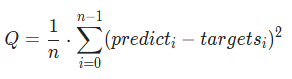
 

где n=1000 - размер тензоров targets и predict. Результат вычислений сохраните в переменной (тензоре) Q. Разместите итоговый тензор Q на CPU.

Программу следует реализовать без использования циклов и генераторов.

P.S. На экран ничего выводить не нужно.

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

targets = torch.rand(1000)
predict = torch.rand(1000)

Q = (targets-predict).pow(2).mean().cpu()
Q

tensor(0.1588)

# Подвиг 6. 

Продолжите программу, в которой заданы следующие тензоры и переменные:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  

w = torch.rand(1, 16) # вектор-строка  
X = torch.rand(16, 16) # матрица 16 x 16  
I = torch.eye(16) # единичная матрица 16 x 16  
lm = 0.5 # значение лямбда  
Необходимо на устройстве device выполнить векторно-матричные вычисления по формуле:  

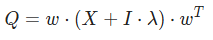
 

Результат вычислений сохранить в переменной Q и переместить на CPU.

Замечание. Здесь установлена версия PyTorch 1.0.1, которая не поддерживает атрибут mT для тензоров. Для транспонирования используйте метод transpose() или permute().

P.S. На экран ничего выводить не нужно.

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

w = torch.rand(1, 16).to(device) # вектор-строка
X = torch.rand(16, 16).to(device) # матрица 16 x 16
I = torch.eye(16).to(device) # единичная матрица 16 x 16
lm = 0.5 # значение лямбда

Q = w @ (X+I*lm) @ w.permute(1, 0).cpu()
Q

tensor([[22.6996]])

# Подвиг 7 (с повторением). 

На рисунке представлена простейшая модель нейронной сети с одним нейроном и сигмоидной функцией активации на выходе:

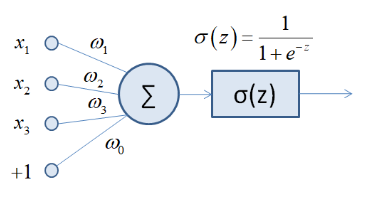

Матрица весовых коэффициентов W и смещение bias задаются командами:

W = torch.rand(3) * 10 - 5  
bias = torch.rand(1) + 1.0  
На вход этой модели подаются сразу несколько векторов, объединенные в пакет (мини-батч) в виде следующей матрицы:

batch_size = 8 # размер мини-батча
X = torch.empty(batch_size, 3).normal_(mean=-1.0, std=3.0)  
Необходимо пропустить каждый образ (каждую строку) тензора X через заданную модель нейронной сети и на выходе получить тензор predict размером batch_size с соответствующими значениями. 

Все вычисления необходимо выполнить на устройстве deivce:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
и реализовать без использования циклов и генераторов.

P.S. На экран ничего выводить не нужно.

In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

W = (torch.rand(3) * 10 - 5).to(device)
bias = (torch.rand(1) + 1.0).to(device)

batch_size = 8 # размер мини-батча
X = torch.empty(batch_size, 3).normal_(mean=-1.0, std=3.0).to(device)

predict = torch.sigmoid(W@X.permute(1, 0)+bias)

In [38]:
t = torch.empty(128).fill_(13)

t.resize_(16, 4)

t.shape

torch.Size([16, 4])